# LAB 3 – Bài 5 (Trang 26): Gom cụm MNIST bằng k-Means và so sánh với nhãn lớp có sẵn

In [1]:
HO_TEN = "Trang Kim Đạt"
MSSV = "6451071018"
print(f"{HO_TEN} – {MSSV}")

Trang Kim Đạt – 6451071018


In [2]:
print(f"{HO_TEN} – {MSSV}")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from tensorflow.keras.datasets import mnist
from sklearn.cluster import KMeans
from scipy.optimize import linear_sum_assignment
from sklearn.metrics import (accuracy_score, classification_report, confusion_matrix,
                             adjusted_rand_score, normalized_mutual_info_score, silhouette_score)

Trang Kim Đạt – 6451071018


c:\Users\trang\AppData\Local\Programs\Python\Python311\Lib\site-packages\google\api_core\_python_version_support.py:254: FutureWarning: You are using a Python version (3.11.9) which Google will stop supporting in new releases of google.api_core once it reaches its end of life (2027-10-24). Please upgrade to the latest Python version, or at least Python 3.12, to continue receiving updates for google.api_core past that date.
  warnings.warn(message, FutureWarning)


## 1. Đọc và tiền xử lý dữ liệu
Ảnh 28×28 được duỗi thành vector 784 chiều và chuẩn hóa về [0, 1]. Nhãn **chỉ dùng để đánh giá**, không đưa vào k-Means.

In [3]:
print(f"{HO_TEN} – {MSSV}")
(train_images, train_labels), (test_images, test_labels) = mnist.load_data()
X_train = train_images.reshape(len(train_images), -1) / 255.0
X_test = test_images.reshape(len(test_images), -1) / 255.0
print("X_train:", X_train.shape, "| X_test:", X_test.shape)

Trang Kim Đạt – 6451071018
X_train: (60000, 784) | X_test: (10000, 784)


## 2. Gom cụm k-Means (k = 10) trên tập train

In [4]:
print(f"{HO_TEN} – {MSSV}")
kmeans = KMeans(n_clusters=10, n_init=3, random_state=42)
cum_train = kmeans.fit_predict(X_train)
print("Số mẫu mỗi cụm:", np.bincount(cum_train))
print("Inertia:", round(kmeans.inertia_, 2))

Trang Kim Đạt – 6451071018
Số mẫu mỗi cụm: [4534 5834 4578 8555 5855 5500 7326 4517 8933 4368]
Inertia: 2352952.65


### Tâm của 10 cụm (hiển thị dạng ảnh)

Trang Kim Đạt – 6451071018


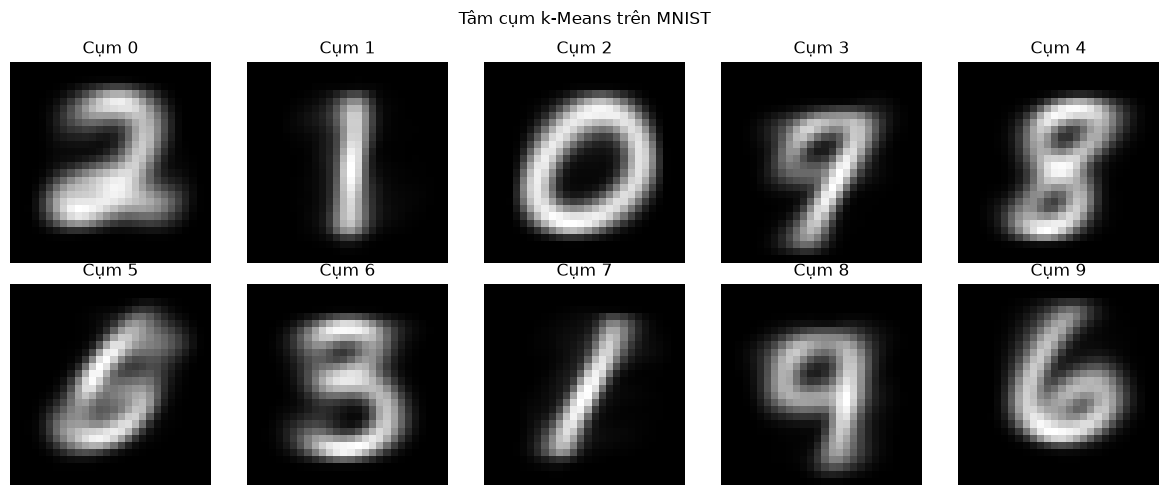

In [5]:
print(f"{HO_TEN} – {MSSV}")
fig, axes = plt.subplots(2, 5, figsize=(12, 5))
for i, ax in enumerate(axes.ravel()):
    ax.imshow(kmeans.cluster_centers_[i].reshape(28, 28), cmap="gray")
    ax.set_title(f"Cụm {i}"); ax.axis("off")
plt.suptitle("Tâm cụm k-Means trên MNIST"); plt.tight_layout(); plt.show()

## 3. So sánh cụm với nhãn lớp có sẵn
Bảng chéo (cụm × nhãn thực), sau đó ghép mỗi cụm với **một** chữ số sao cho tổng số mẫu khớp là lớn nhất (thuật toán Hungarian) để tính confusion matrix và các độ đo phân lớp.

Trang Kim Đạt – 6451071018


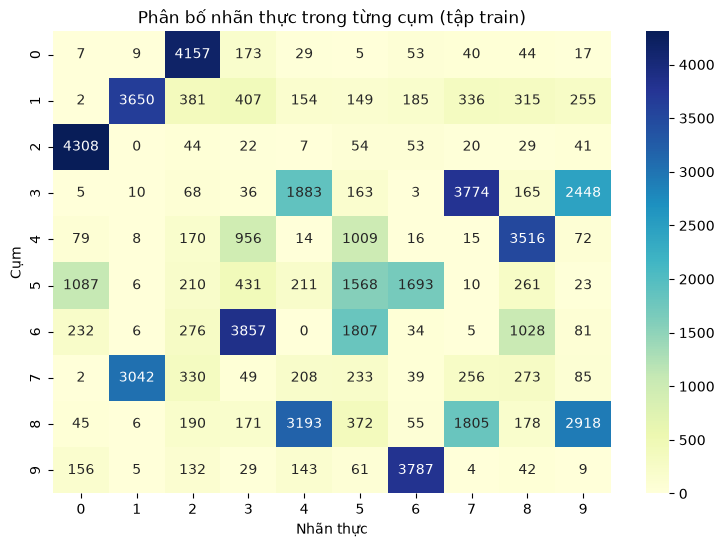

In [6]:
print(f"{HO_TEN} – {MSSV}")
bang_cheo = pd.crosstab(pd.Series(cum_train, name="Cụm"), pd.Series(train_labels, name="Nhãn thực"))
plt.figure(figsize=(9, 6))
sns.heatmap(bang_cheo, annot=True, fmt="d", cmap="YlGnBu")
plt.title("Phân bố nhãn thực trong từng cụm (tập train)")
plt.show()

In [7]:
print(f"{HO_TEN} – {MSSV}")
def ghep_cum_nhan(cum, nhan, so_lop=10):
    """Ghép mỗi cụm với 1 nhãn (Hungarian) -> từ điển {cụm: nhãn}."""
    ma_tran = np.zeros((so_lop, so_lop), dtype=int)
    for c, y in zip(cum, nhan):
        ma_tran[c, y] += 1
    hang, cot = linear_sum_assignment(-ma_tran)
    return dict(zip(hang, cot))

anh_xa = ghep_cum_nhan(cum_train, train_labels)
print("Ánh xạ cụm -> chữ số:", anh_xa)

y_pred_train = np.array([anh_xa[c] for c in cum_train])
print("Accuracy (tập train):", round(accuracy_score(train_labels, y_pred_train), 4))
print("Adjusted Rand Index :", round(adjusted_rand_score(train_labels, cum_train), 4))
print("Normalized Mutual Information:", round(normalized_mutual_info_score(train_labels, cum_train), 4))

Trang Kim Đạt – 6451071018
Ánh xạ cụm -> chữ số: {np.int64(0): np.int64(2), np.int64(1): np.int64(1), np.int64(2): np.int64(0), np.int64(3): np.int64(7), np.int64(4): np.int64(8), np.int64(5): np.int64(5), np.int64(6): np.int64(3), np.int64(7): np.int64(9), np.int64(8): np.int64(4), np.int64(9): np.int64(6)}
Accuracy (tập train): 0.5316
Adjusted Rand Index : 0.3634
Normalized Mutual Information: 0.4978


Trang Kim Đạt – 6451071018


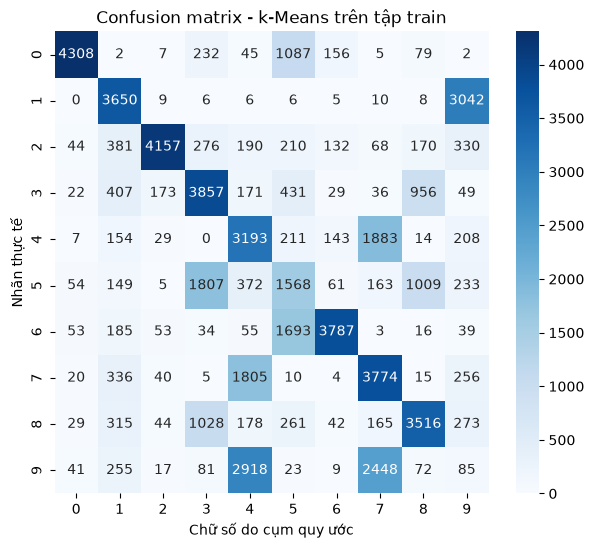

              precision    recall  f1-score   support

           0     0.9410    0.7273    0.8205      5923
           1     0.6256    0.5414    0.5805      6742
           2     0.9169    0.6977    0.7924      5958
           3     0.5265    0.6291    0.5732      6131
           4     0.3574    0.5466    0.4322      5842
           5     0.2851    0.2892    0.2872      5421
           6     0.8670    0.6399    0.7363      5918
           7     0.4411    0.6024    0.5093      6265
           8     0.6005    0.6009    0.6007      5851
           9     0.0188    0.0143    0.0162      5949

    accuracy                         0.5316     60000
   macro avg     0.5580    0.5289    0.5349     60000
weighted avg     0.5606    0.5316    0.5375     60000



In [8]:
print(f"{HO_TEN} – {MSSV}")
cm = confusion_matrix(train_labels, y_pred_train)
plt.figure(figsize=(7, 6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")
plt.xlabel("Chữ số do cụm quy ước"); plt.ylabel("Nhãn thực tế"); plt.title("Confusion matrix - k-Means trên tập train")
plt.show()
print(classification_report(train_labels, y_pred_train, digits=4))

## 4. Áp dụng mô hình k-Means cho tập test
Gán mỗi ảnh test vào cụm gần nhất, dùng cùng ánh xạ cụm → chữ số đã tìm được ở tập train.

Trang Kim Đạt – 6451071018
Accuracy (tập test): 0.5438
Adjusted Rand Index : 0.3771
              precision    recall  f1-score   support

           0     0.9367    0.7398    0.8267       980
           1     0.6639    0.5692    0.6129      1135
           2     0.9083    0.6812    0.7785      1032
           3     0.5326    0.6802    0.5974      1010
           4     0.3612    0.5682    0.4416       982
           5     0.3030    0.2646    0.2825       892
           6     0.8526    0.7004    0.7691       958
           7     0.4366    0.5866    0.5006      1028
           8     0.6116    0.6191    0.6153       974
           9     0.0084    0.0059    0.0070      1009

    accuracy                         0.5438     10000
   macro avg     0.5615    0.5415    0.5432     10000
weighted avg     0.5641    0.5438    0.5456     10000



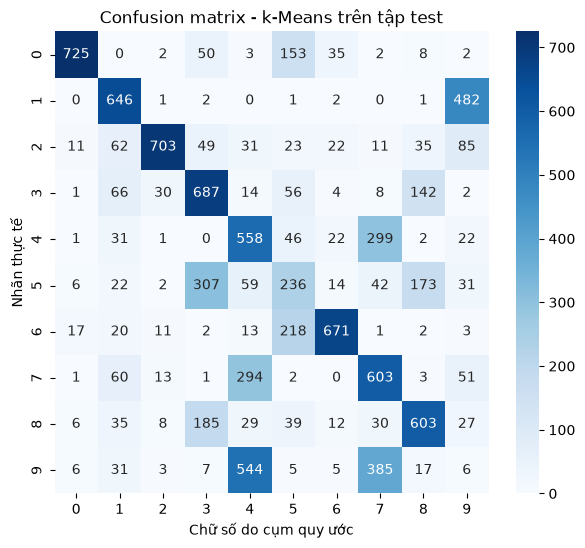

In [9]:
print(f"{HO_TEN} – {MSSV}")
cum_test = kmeans.predict(X_test)
y_pred_test = np.array([anh_xa[c] for c in cum_test])
print("Accuracy (tập test):", round(accuracy_score(test_labels, y_pred_test), 4))
print("Adjusted Rand Index :", round(adjusted_rand_score(test_labels, cum_test), 4))
print(classification_report(test_labels, y_pred_test, digits=4))
cm = confusion_matrix(test_labels, y_pred_test)
plt.figure(figsize=(7, 6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")
plt.xlabel("Chữ số do cụm quy ước"); plt.ylabel("Nhãn thực tế"); plt.title("Confusion matrix - k-Means trên tập test")
plt.show()

## 5. Nhận xét

In [10]:
print(f"{HO_TEN} – {MSSV}")
f1 = classification_report(test_labels, y_pred_test, output_dict=True, zero_division=0)
tot = max(range(10), key=lambda d: f1[str(d)]["f1-score"])
te = min(range(10), key=lambda d: f1[str(d)]["f1-score"])
print(f"Chữ số được gom tốt nhất: {tot} (F1 = {f1[str(tot)]['f1-score']:.3f})")
print(f"Chữ số được gom kém nhất: {te} (F1 = {f1[str(te)]['f1-score']:.3f})")

Trang Kim Đạt – 6451071018
Chữ số được gom tốt nhất: 0 (F1 = 0.827)
Chữ số được gom kém nhất: 9 (F1 = 0.007)


- k-Means là thuật toán **không giám sát** nên không biết nhãn; các cụm chỉ dựa trên khoảng cách Euclide giữa các vector pixel. Vì vậy Accuracy (~50–60%) thấp hơn nhiều so với Neural Network có giám sát (~97–98%).
- Những chữ số có hình dạng đặc trưng và ít biến thể như **0, 2, 6** được gom tốt nhất (F1 ≈ 0,77–0,83); các chữ số dễ nhầm lẫn như **4 – 9**, **3 – 5 – 8**, **7 – 9** bị trộn vào cùng cụm (xem bảng chéo và confusion matrix); chữ số **9** gần như không tạo được cụm riêng (F1 ≈ 0) vì bị trộn với 4 và 7.
- Cùng một chữ số có thể bị chia ra nhiều cụm (do khác kiểu viết, độ nghiêng) trong khi các chữ số giống nhau bị gộp thành một cụm, nên k = 10 không đảm bảo mỗi cụm ứng với đúng một chữ số.
- Các độ đo ARI, NMI cho thấy mức độ tương đồng giữa phân cụm và nhãn thực ở mức trung bình; k-Means vẫn hữu ích như bước khám phá cấu trúc dữ liệu khi chưa có nhãn.